# Basics of Data Visualization

Data visualization is the process of **representing data visually** to understand patterns, trends, and relationships.

Key principles:
- Choose the right type of plot for your data (categorical vs numeric).
- Label axes (with units) and provide a title.
- Use color and shapes to highlight differences — not as decoration.
- Keep it simple and clear for interpretation.

| Question | Data | Plot |
|---|---|---|
| How many in each category? | 1 categorical | **Bar plot** |
| What does the distribution look like? | 1 numeric | **Histogram**, density |
| What are the spread and the outliers? | 1 numeric (± groups) | **Boxplot** |
| How do two variables relate? | 2 numeric | **Scatter plot** |
| How does something change over time? | numeric vs time | **Line plot** |

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. Example Dataset

We build a small data frame of 40 people with age, height, weight, sex and a sport category.

In [2]:
set.seed(2024)
n <- 40
people <- data.frame(
  age    = round(runif(n, 20, 45)),
  sex    = factor(sample(c("Female", "Male"), n, replace = TRUE)),
  sport  = factor(sample(c("Football", "Swimming", "Running", "None"), n, replace = TRUE,
                         prob = c(0.3, 0.2, 0.2, 0.3)))
)
people$height <- round(ifelse(people$sex == "Male", 178, 165) + rnorm(n, 0, 6))
people$weight <- round(0.9 * people$height - 85 + ifelse(people$sport == "None", 6, 0) + rnorm(n, 0, 5))
head(people)

,age,sex,sport,height,weight
,<dbl>,<fct>,<fct>,<dbl>,<dbl>
1,41,Male,Football,188,95
2,28,Male,Football,183,82
3,37,Female,None,168,77
4,37,Female,Football,166,65
5,31,Female,Running,175,66
6,38,Male,None,177,82


## 2. The Four Core Plots in Base R

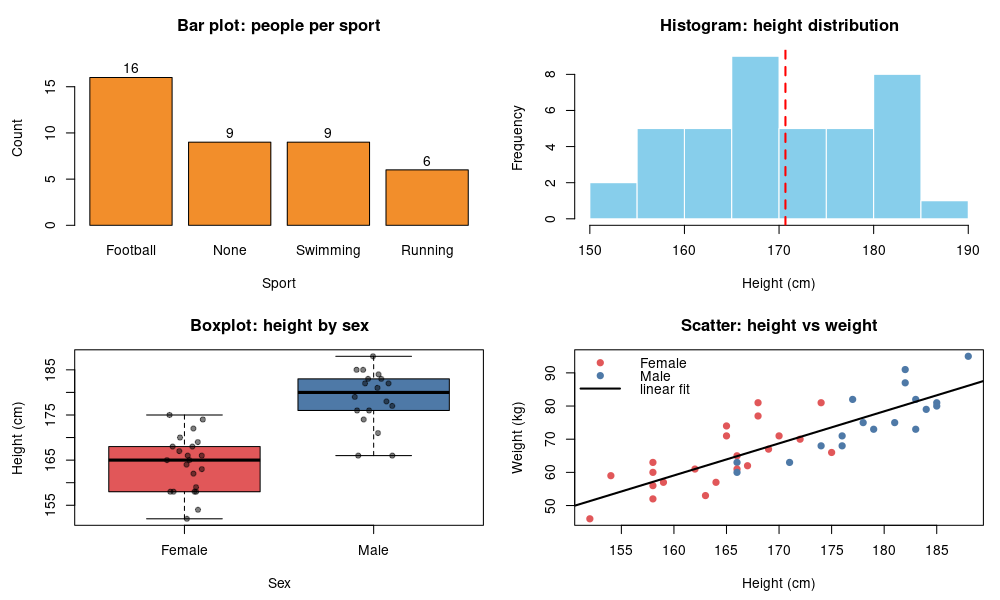

In [3]:
par(mfrow = c(2, 2), mar = c(4.5, 4.5, 3, 1))

# Bar plot - categorical
counts <- sort(table(people$sport), decreasing = TRUE)
bp <- barplot(counts, col = "#F28E2B", ylim = c(0, max(counts) + 3),
              main = "Bar plot: people per sport", xlab = "Sport", ylab = "Count")
text(bp, counts + 1, counts)

# Histogram - one numeric variable
hist(people$height, breaks = 10, col = "skyblue", border = "white",
     main = "Histogram: height distribution", xlab = "Height (cm)", ylab = "Frequency")
abline(v = mean(people$height), col = "red", lwd = 2, lty = 2)

# Boxplot - numeric by group
boxplot(height ~ sex, data = people, col = c("#E15759", "#4E79A7"),
        main = "Boxplot: height by sex", xlab = "Sex", ylab = "Height (cm)")
stripchart(height ~ sex, data = people, vertical = TRUE, method = "jitter",
           pch = 19, col = adjustcolor("black", 0.5), add = TRUE)

# Scatter plot - two numeric variables
plot(people$height, people$weight, pch = 19, col = ifelse(people$sex == "Male", "#4E79A7", "#E15759"),
     main = "Scatter: height vs weight", xlab = "Height (cm)", ylab = "Weight (kg)")
abline(lm(weight ~ height, data = people), col = "black", lwd = 2)
legend("topleft", c("Female", "Male", "linear fit"), col = c("#E15759", "#4E79A7", "black"),
       pch = c(19, 19, NA), lty = c(NA, NA, 1), lwd = c(NA, NA, 2), bty = "n")

*Insight: Overlaying the raw points on the boxplot (`stripchart(..., add = TRUE)`) shows the sample size and the actual data behind the summary. A boxplot of 5 points and a boxplot of 5,000 points look identical otherwise.*

## 3. The Grammar of Graphics with `ggplot2`

`ggplot2` builds plots in **layers**: data → aesthetic mappings (`aes`) → geometric objects (`geom_*`) → scales, facets and themes. It is the most widely used plotting system in R.

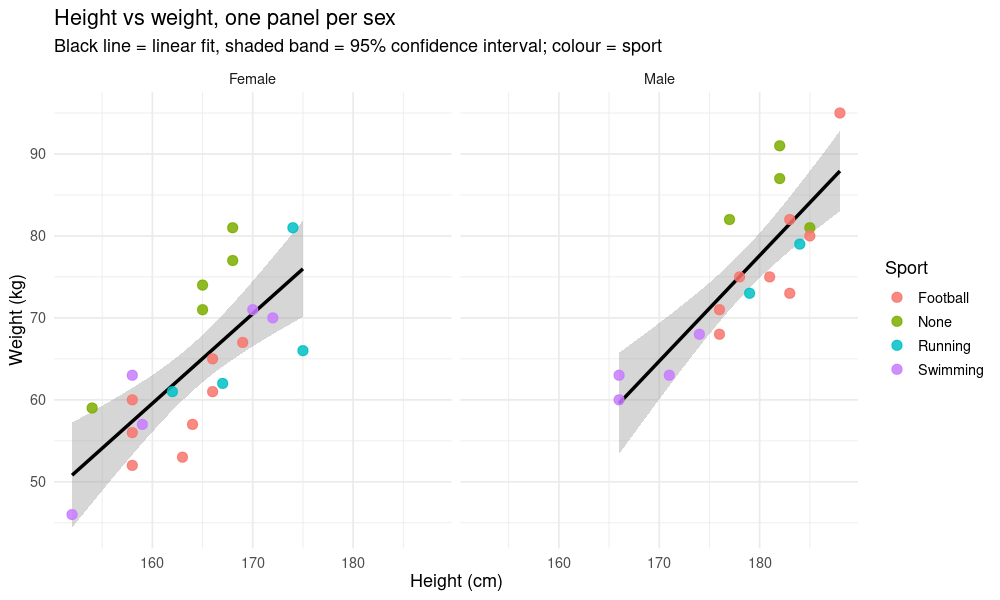

In [4]:
suppressPackageStartupMessages(library(ggplot2))

ggplot(people, aes(x = height, y = weight)) +
  geom_smooth(method = "lm", formula = y ~ x, se = TRUE, colour = "black") +
  geom_point(aes(colour = sport), size = 3, alpha = 0.85) +
  facet_wrap(~ sex) +
  labs(title = "Height vs weight, one panel per sex",
       subtitle = "Black line = linear fit, shaded band = 95% confidence interval; colour = sport",
       x = "Height (cm)", y = "Weight (kg)", colour = "Sport") +
  theme_minimal(base_size = 13)

## 4. Good vs Misleading Charts

The same numbers can tell very different stories depending on design choices. A truncated y-axis on a bar chart exaggerates small differences, because bar **length** is what our eyes compare.

Q4 vs Q1 actual growth: 3.9 %


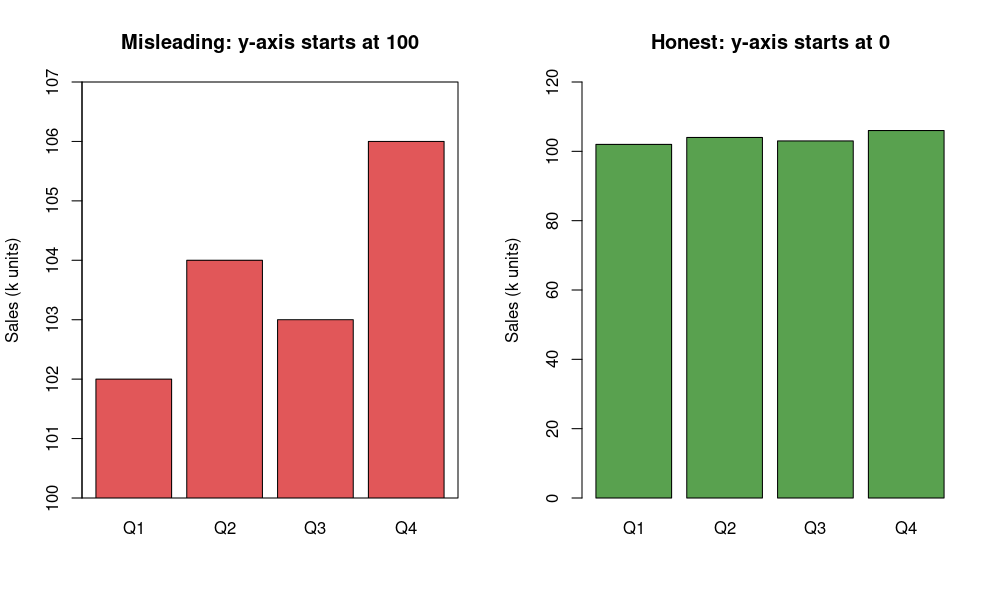

In [5]:
sales <- c(Q1 = 102, Q2 = 104, Q3 = 103, Q4 = 106)

par(mfrow = c(1, 2))
barplot(sales, ylim = c(100, 107), xpd = FALSE, col = "#E15759",
        main = "Misleading: y-axis starts at 100", ylab = "Sales (k units)")
box()
barplot(sales, ylim = c(0, 120), col = "#59A14F",
        main = "Honest: y-axis starts at 0", ylab = "Sales (k units)")
cat("Q4 vs Q1 actual growth:", round(100 * (sales["Q4"] / sales["Q1"] - 1), 1), "%\n")

*Insight: In the left chart, Q4 looks about **three times** taller than Q1; the real growth is about 4%. Bar charts must start at zero. If you need to show small changes, use a line or dot plot, where the axis doesn't have to start at zero.*

## Real-World Use Case or Analogy

A chart is a **map** of your data:

- A **bar plot** is a city map with a pin per district — it tells you how many of each.
- A **histogram** is a terrain map — it shows where the mountains (common values) and valleys (rare values) are.
- A **boxplot** is the summary card at a hiking trailhead: lowest point, highest point, and where most of the trail lies.
- A **scatter plot** is a map of two roads, showing whether they run in parallel.

A misleading chart is like a map with a distorted scale — every street is technically in the right place, but you'll badly misjudge the distances.